In [25]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd().parent

df = pd.read_parquet(str(BASE_DIR / "data/gold/power_market_15min"))
df.head()

,start_time_utc,end_time_utc,start_time_helsinki,date_start_helsinki,hour_start_helsinki,minute_start_helsinki,day_of_week,is_weekend,is_peak_hour,wind_mw,nuclear_mw,hydro_mw,consumption_mw,price_eur_per_mwh,selected_generation_mw,net_load_ex_solar_mw,selected_gen_balance_mw,wind_share_selected_ratio
0,2026-10-22 00:00:00,2026-10-22 00:15:00,2026-10-22 03:00:00,2026-10-22,3,0,5,False,False,5279.78,2089.52,1761.08,9979.98,15.10,9130.38,4700.20,-849.60,0.578
1,2026-10-22 00:15:00,2026-10-22 00:30:00,2026-10-22 03:15:00,2026-10-22,3,15,5,False,False,5167.56,2088.68,1760.65,9937.73,15.68,9016.89,4770.17,-920.84,0.573
2,2026-10-22 00:30:00,2026-10-22 00:45:00,2026-10-22 03:30:00,2026-10-22,3,30,5,False,False,5068.69,2090.13,1758.48,9922.32,17.07,8917.30,4853.63,-1005.02,0.568
3,2026-10-22 00:45:00,2026-10-22 01:00:00,2026-10-22 03:45:00,2026-10-22,3,45,5,False,False,5015.53,2088.91,1755.84,9911.33,18.51,8860.28,4895.80,-1051.05,0.566
4,2026-10-22 01:00:00,2026-10-22 01:15:00,2026-10-22 04:00:00,2026-10-22,4,0,5,False,False,4921.06,2089.34,1775.10,9855.39,13.44,8785.50,4934.33,-1069.89,0.560


In [26]:
# sort by time (asc)
df.sort_values("start_time_utc")

q_low, q_high = 0.20, 0.80
eff = 0.95 # One-way efficiency (charge OR discharge)
rte = eff * eff # Round-trip efficiency : energy out / energy in (-0.9025)
min_spread_eur = 5.0 # Minimum net margin (EUR/MWh) required to bother trading

'''
1. Assign each 15-min slot to its day-ahead delivery day (CET/CEST)
The Nordic/EU day-ahead market clears per CET delivery day, not per Helsinki day.
'''
df["trade_date_cet"] = (
    pd.to_datetime(df["start_time_utc"], utc=True)
    .dt.tz_convert("Europe/Brussels") # Shift to CET/CEST wall-clock time
    .dt.date
)

In [27]:
''' 
2. Per-day price thresholds
Day-ahead prices for the whole delivery day are known the day before, so using the
same-day distribution does not leak future information. A per-day quantile also
adapts automatically to seasons and price levels, unlike a hard-coded EUR threshold.
'''

grouped_price = df.groupby("trade_date_cet")["price_eur_per_mwh"]
df["buy_th"] = grouped_price.transform(lambda x: x.quantile(q_low)) #cheap -> charge
df["sell_th"] = grouped_price.transform(lambda x: x.quantile(q_high)) #expensive -> discharge

In [28]:
''' 
3. Check if trading is worh on this day
Selling at the high threshold only return 'rte' of the energy we bought,
so we compare the efficiency-adjusted revenue against the purchase cost + a safety margin.
On flat-price days this switch is False, which prevents loss-making cycling.
'''

df["is_profitable_day"] = (
    df["sell_th"] * rte > df["buy_th"] + min_spread_eur
)
df["charge_signal"] = df["is_profitable_day"] & (df["price_eur_per_mwh"] <= df["buy_th"])
df["discharge_signal"] = df["is_profitable_day"] & (df["price_eur_per_mwh"] >= df["sell_th"])

In [29]:
df[["start_time_helsinki", "trade_date_cet", "price_eur_per_mwh", "buy_th", "sell_th"]].head(10)

,start_time_helsinki,trade_date_cet,price_eur_per_mwh,buy_th,sell_th
0,2026-10-22 03:00:00,2026-10-22,15.10,18.384,27.91
1,2026-10-22 03:15:00,2026-10-22,15.68,18.384,27.91
2,2026-10-22 03:30:00,2026-10-22,17.07,18.384,27.91
3,2026-10-22 03:45:00,2026-10-22,18.51,18.384,27.91
4,2026-10-22 04:00:00,2026-10-22,13.44,18.384,27.91
5,2026-10-22 04:15:00,2026-10-22,15.41,18.384,27.91
6,2026-10-22 04:30:00,2026-10-22,12.54,18.384,27.91
7,2026-10-22 04:45:00,2026-10-22,16.58,18.384,27.91
8,2026-10-22 05:00:00,2026-10-22,13.53,18.384,27.91
9,2026-10-22 05:15:00,2026-10-22,15.86,18.384,27.91


In [30]:
''' 
Things to know : 
1. The size of battery is 10 MWh, but we only use between 1.0 MWh (10%) and 9.0 MWh (90%), tops, to protect the battery span life.
2. Heat loss (efficiency: 0.95) : if you buy energy of 1.0 MWh from outside, only 0.95 MWh remains because of the heat loss.
'''
CAPACITY_MWH = 10.0
MIN_ENERGY = 1.0
MAX_ENERGY = 9.0
MAX_STEP_MWH = 5.0 * 0.25 #  Maximum energy that can be transferred in 15 minutes (5 MW * 0.25 h = 1.25 MWh)
EFF = 0.95
MIN_SPREAD = 5.0

In [31]:
# Simulation begins

current_energy = 5.0
results = []

# Read and make a decision at each 15-min interval.
for row in df.itertuples():
    price = row.price_eur_per_mwh
    buy_th = row.buy_th
    sell_th = row.sell_th

    # Check if it is profitable day (selling price * round trip efficiency > buying price + minimum margin)
    is_profitable_day = (sell_th * EFF * EFF) > (buy_th + MIN_SPREAD)

    action = "IDLE"
    grid_mwh = 0.0 # Amount of electricity traded with the grid
    revenue = 0.0 # Money earned (+) or spent (-) during this 15-minute interval

    # [Condition 1: Charging] When the price is negative or profitable day, and below buy_th (provided the battery has free space)
    if (price < 0 or (is_profitable_day and price <= buy_th)) and current_energy < MAX_ENERGY:
        action = "CHARGE"
        # Choose the smaller of the amount needed to fill the gap and the 15-minute maximum output (1.25 MWh)
        needed_from_grid = (MAX_ENERGY - current_energy) / EFF
        grid_mwh = min(MAX_STEP_MWH, needed_from_grid)

        current_energy += grid_mwh * EFF 
        revenue = -(grid_mwh * price)
    #[Condition 2: Discharging] When profitable and above sell_th (provided the battery has energy available)
    elif is_profitable_day and price >= sell_th and current_energy > MIN_ENERGY:
        action = "DISCHARGE"
        # Choose the smaller of the available battery energy and the 15-minute maximum output (1.25 MWh)
        available_in_battery = current_energy - MIN_ENERGY
        batt_out_mwh = min(MAX_STEP_MWH, available_in_battery)

        current_energy -= batt_out_mwh
        grid_mwh = batt_out_mwh * EFF
        revenue = +(grid_mwh * price)
    # Result   
    results.append({
        "start_time_helsinki": row.start_time_helsinki,
        "price_eur_per_mwh": price,
        "buy_th": round(buy_th, 2),
        "sell_th": round(sell_th, 2),
        "action": action,
        "grid_mwh": round(grid_mwh, 3),
        "soc_mwh": round(current_energy, 3),
        "soc_pct": round((current_energy / CAPACITY_MWH) * 100, 1),
        "revenue_eur": round(revenue, 2)
    })

In [32]:
sim_df = pd.DataFrame(results)

print("=== Number of Actions by Type ===")
print(sim_df["action"].value_counts())

print(f"\nTotal Cumulative Cash Revenue: {sim_df['revenue_eur'].sum():.2f} EUR")
print(f"Initial Battery Level: 5.0 MWh -> Final Battery Level: {current_energy:.3f} MWh")

sim_df.head(15)

=== Number of Actions by Type ===
action
IDLE         246
CHARGE        23
DISCHARGE     19
Name: count, dtype: int64

Total Cumulative Cash Revenue: 374.88 EUR
Initial Battery Level: 5.0 MWh -> Final Battery Level: 9.000 MWh


,start_time_helsinki,price_eur_per_mwh,buy_th,sell_th,action,grid_mwh,soc_mwh,soc_pct,revenue_eur
0,2026-10-22 03:00:00,15.10,18.38,27.91,CHARGE,1.250,6.188,61.9,-18.88
1,2026-10-22 03:15:00,15.68,18.38,27.91,CHARGE,1.250,7.375,73.8,-19.60
2,2026-10-22 03:30:00,17.07,18.38,27.91,CHARGE,1.250,8.562,85.6,-21.34
3,2026-10-22 03:45:00,18.51,18.38,27.91,IDLE,0.000,8.562,85.6,0.00
4,2026-10-22 04:00:00,13.44,18.38,27.91,CHARGE,0.461,9.000,90.0,-6.19
5,2026-10-22 04:15:00,15.41,18.38,27.91,IDLE,0.000,9.000,90.0,0.00
6,2026-10-22 04:30:00,12.54,18.38,27.91,IDLE,0.000,9.000,90.0,0.00
7,2026-10-22 04:45:00,16.58,18.38,27.91,IDLE,0.000,9.000,90.0,0.00
8,2026-10-22 05:00:00,13.53,18.38,27.91,IDLE,0.000,9.000,90.0,0.00
9,2026-10-22 05:15:00,15.86,18.38,27.91,IDLE,0.000,9.000,90.0,0.00


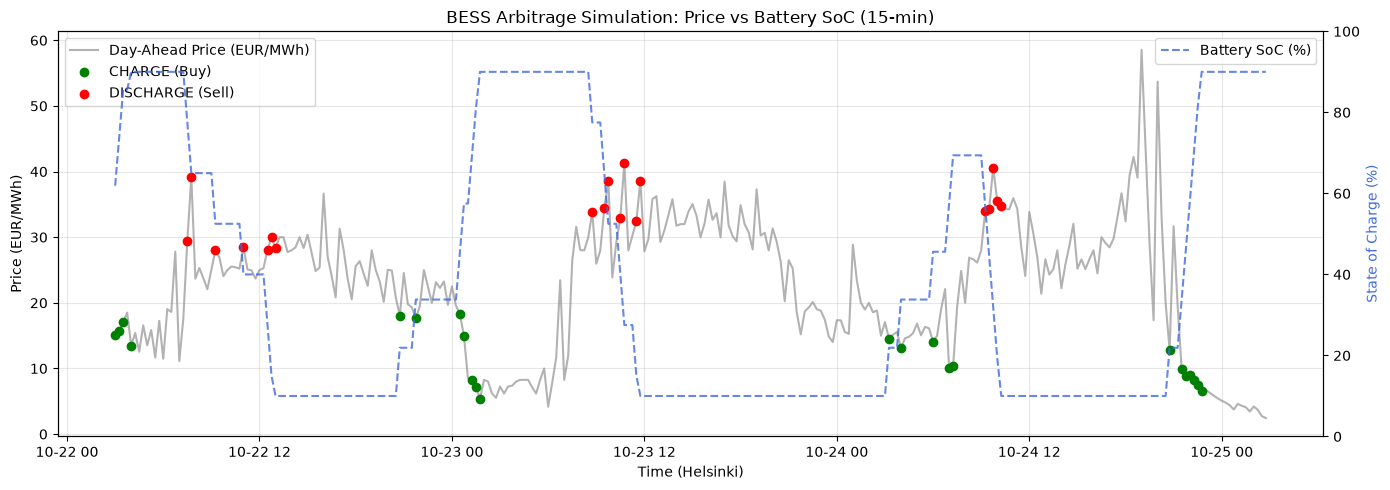

In [33]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 5))

# Left axis: Electricity price (grey line) + charging (green dots) / discharging (red dots)
ax1.plot(sim_df["start_time_helsinki"], sim_df["price_eur_per_mwh"], color="gray", alpha=0.6, label="Day-Ahead Price (EUR/MWh)")

charge_pts = sim_df[sim_df["action"] == "CHARGE"]
discharge_pts = sim_df[sim_df["action"] == "DISCHARGE"]

ax1.scatter(charge_pts["start_time_helsinki"], charge_pts["price_eur_per_mwh"], color="green", label="CHARGE (Buy)", zorder=5)
ax1.scatter(discharge_pts["start_time_helsinki"], discharge_pts["price_eur_per_mwh"], color="red", label="DISCHARGE (Sell)", zorder=5)

ax1.set_ylabel("Price (EUR/MWh)")
ax1.set_xlabel("Time (Helsinki)")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

# Right axis: Battery state of charge (%) shown as a blue dashed line
ax2 = ax1.twinx()
ax2.plot(sim_df["start_time_helsinki"], sim_df["soc_pct"], color="royalblue", linestyle="--", alpha=0.8, label="Battery SoC (%)")
ax2.set_ylabel("State of Charge (%)", color="royalblue")
ax2.set_ylim(0, 100)
ax2.legend(loc="upper right")

plt.title("BESS Arbitrage Simulation: Price vs Battery SoC (15-min)")
plt.tight_layout()
plt.show()

In [34]:
import numpy as np
from scipy import sparse
from scipy.optimize import linprog

def lp_profit(prices, soc0, soc_end, eff, e_min, e_max, step_max):
    n = len(prices)
    I = sparse.identity(n, format="csr")
    prev = sparse.diags([-np.ones(n - 1)], [-1], format="csr")   # picks soc[t-1]

    # Variables: [charge (grid side), discharge (battery side), soc]; minimise cost
    cost = np.concatenate([prices, -prices * eff, np.zeros(n)])

    # soc[t] - soc[t-1] - eff * charge[t] + discharge[t] = 0
    A_eq = sparse.hstack([-eff * I, I, I + prev], format="csr")
    b_eq = np.zeros(n)
    b_eq[0] = soc0

    bounds = [(0, step_max)] * (2 * n) + [(e_min, e_max)] * (n - 1) + [(soc_end, soc_end)]
    res = linprog(cost, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    assert res.success, res.message
    return -res.fun

# Pin final SoC to the baseline's so both are compared on cash alone
lp = lp_profit(df["price_eur_per_mwh"].values, 5.0, current_energy,
               EFF, MIN_ENERGY, MAX_ENERGY, MAX_STEP_MWH)
base = sim_df["revenue_eur"].sum()

assert base <= lp + 1e-6, "Baseline exceeded the LP upper bound -> bug"
print(f"Baseline: {base:.2f} EUR | LP optimum: {lp:.2f} EUR | Capture: {base / lp * 100:.1f}%")

Baseline: 374.88 EUR | LP optimum: 955.92 EUR | Capture: 39.2%
